# UMUD Challenge: CNN pipeline for muscle architecture (PA, FL, MT)

**What this notebook does.** The training data has *masks* (aponeuroses, fascicles), not PA / FL / MT numbers, so the
main pipeline (**Part A**) is: two U-Nets segment the aponeuroses and the fascicles, then geometry turns the masks into
pennation angle, fascicle length and muscle thickness. **Part B** (optional) trains the direct-regression CNN you
originally had in mind on numbers computed by Part A, and can be ensembled with it.

| Your step | Where |
|---|---|
| 1. Resize keeping physical (mm) spacing, pad | §2 scale & field of view, §3 preprocessing |
| 2. Grid search: input size x contrast (CLAHE), 5-fold CV, subsample, 100 epochs | §6 (A) and §11 (B, adds log-FL target) |
| 3. Grid search: batch size x learning rate, full set, 5-fold CV | §7 (A), §12 (B) |
| 4. Final model (200 epochs), metrics table (MSE, MAE, MPE ...), submission | §8-§9 (A), §13 (B), §14 |
| 5. Grad-CAM++ | §10 (A, segmentation), §13 (B, one map per output) |

**Choices made for you (change them in the settings cell):**
* "Batch size and mini batch" is treated as **batch size x learning rate**.
* Epoch counts are *maximums*; training stops early when validation stops improving (`*_patience`).
  Set patience = epochs to always run the full count.
* Images are grouped in blocks of consecutive file numbers before any split, because neighbouring files are often
  frames of one video (the starter notebook found this in the test set). This keeps near-copies out of the
  validation folds.
* Pixel -> mm comes from the depth printed on each screen (OCR) divided by the height of the scan area.
  Check the scale review table in §2 and add overrides for anything it flags.

**Run time.** With the default grids, Part A is ~120 CV runs on the subsample + ~90 CV runs on the full set.
That does not fit one 12-h Kaggle GPU session: every grid writes its results to CSV after each fold and
resumes where it stopped, so you can run it over several sessions (save the output and attach it as a dataset,
or keep the working folder). Shrink `sizes`, `clahe_clips`, `batch_sizes`, `lrs` or `n_folds` to go faster.
Set the environment variable `UMUD_FAST_DEV=1` for a 5-minute smoke test of the whole notebook.

## 0. Settings

In [27]:
import os, re, math, time, random, hashlib, shutil, subprocess, warnings, multiprocessing
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
import numpy as np, pandas as pd, cv2
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

warnings.filterwarnings('ignore', category=UserWarning)
cv2.setNumThreads(1)

FAST_DEV = True
ROOT = Path(os.environ.get('UMUD_ROOT', '.'))
OUT = Path(os.environ.get('UMUD_OUT', '/kaggle/working' if Path('/kaggle/working').exists() else './umud_outputs'))
OUT.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,
    # --- splits ---
    holdout_frac=0.15,        # kept aside for the final metrics table (step 4)
    group_block=25,           # consecutive file numbers form one group (frames of one video / participant)
    n_folds=5,
    # --- masks ---
    fasc_dilate_px=2,         # fascicle masks are 1-px lines: thicken before resizing (as the starter notebook does)
    # --- scale ---
    mmpp_range=(0.02, 0.25),  # plausible mm per pixel of the original screenshots
    scale_overrides=None,     # optional CSV with columns name,set and mm_per_px or depth_mm (see §2)
    # --- step 2: input size x contrast, 5-fold CV on a subsample ---
    subsample_frac=0.20,
    sizes=[256, 384, 512],    # canvas side in pixels; the canvas always covers the same physical width (P_MM)
    clahe_clips=[0.0, 1.0, 2.0, 3.0],   # 0 = no CLAHE; 1-3 is the usual range for ultrasound
    step2_epochs=100, step2_patience=12, step2_batch=8, step2_lr=3e-4,
    # --- step 3: batch size x learning rate, 5-fold CV on the full training set ---
    batch_sizes=[4, 8, 16],
    lrs=[1e-4, 3e-4, 1e-3],
    step3_epochs=60, step3_patience=10,
    # --- step 4: final models ---
    final_epochs=200, final_patience=25,
    reuse_saved=True,         # load final_*.pt from OUT instead of retraining if present
    # --- geometry ---
    thr_apo=0.5, thr_fasc=0.5,
    clip_ranges=dict(pa_deg=(5, 45), fl_mm=(30, 200), mt_mm=(10, 50)),   # test-set ranges stated by the organisers
    # --- part B: direct regression CNN on labels computed by part A ---
    run_part_b=True,
    b_top_k_preproc=2,        # best size/contrast combos from step 2 to re-test for the regressor
    b_log_fl=[False, True],   # log-transform fascicle length target?
    final_submission='A',     # 'A', 'B' or 'ensemble'
    num_workers=2,
)
if FAST_DEV:
    CFG.update(holdout_frac=0.2, group_block=1, n_folds=2, subsample_frac=1.0, sizes=[64, 96], clahe_clips=[0.0, 2.0],
               step2_epochs=2, step2_patience=2, step2_batch=4, batch_sizes=[2, 4], lrs=[1e-3],
               step3_epochs=2, step3_patience=2, final_epochs=3, final_patience=3, b_top_k_preproc=1,
               num_workers=0, reuse_saved=False, run_part_b=False)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG['seed'])

# chart style: one blue for single series, blue/orange for pairs, single-hue blue for heatmaps
BLUE, ORANGE, AQUA, INK = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#2a78d6', '#1c5cab', '#0d366b'])
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
                     'grid.linewidth': .6, 'lines.linewidth': 2, 'figure.dpi': 100, 'axes.titlesize': 11})
def show(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight', dpi=110)
    plt.show(); plt.close(fig)

print('device:', DEVICE, '| fast dev:', FAST_DEV, '| outputs ->', OUT)

device: cpu | fast dev: True | outputs -> umud_outputs


## 1. Data inventory
Image and mask files share a name. Masks can be a different size from their image and some are stored with an
inverted ImageJ colour table, so the foreground is taken as the *minority* class after reading.

In [28]:
DATA = next(ROOT.rglob('sample_submission.csv')).parent
IMG_EXT = {'.tif', '.tiff', '.png', '.jpg', '.jpeg', '.bmp'}

def find_dir(prefix):
    c = sorted(d for d in DATA.iterdir() if d.is_dir() and d.name.startswith(prefix))
    if not c:
        raise FileNotFoundError(f'no folder starting with {prefix} in {DATA}')
    return c[-1]                      # highest version if several (_v1, _v2)

def list_images(d):
    return sorted(p for p in d.rglob('*') if p.suffix.lower() in IMG_EXT and not p.name.startswith('.'))

APO_IMG, APO_MASK, FASC_IMG, FASC_MASK, TEST_DIR = (find_dir(p) for p in
    ['apo_imgs', 'apo_masks', 'fasc_imgs', 'fasc_masks', 'test_images'])

def pair(img_dir, mask_dir, set_name):
    masks = {p.stem: p for p in list_images(mask_dir)}
    imgs = list_images(img_dir)
    rows = [dict(set=set_name, key=f'{set_name}/{p.stem}', name=p.name, img=str(p), mask=str(masks[p.stem]))
            for p in imgs if p.stem in masks]
    print(f'{set_name:5s}: {len(rows)} image/mask pairs ({len(imgs) - len(rows)} images without a mask skipped)')
    return pd.DataFrame(rows)

def add_groups(df, block):
    num = pd.to_numeric(df['name'].str.extract(r'(\d+)(?!.*\d)')[0], errors='coerce')
    num = num.fillna(pd.Series(np.arange(len(df)), index=df.index))
    df['group'] = df['set'] + '_' + (num // block).astype(int).astype(str)
    return df

apo_df = add_groups(pair(APO_IMG, APO_MASK, 'apo'), CFG['group_block'])
fasc_df = add_groups(pair(FASC_IMG, FASC_MASK, 'fasc'), CFG['group_block'])
test_df = pd.DataFrame([dict(set='test', key=f'test/{p.stem}', name=p.name, img=str(p), mask=None, group='test')
                        for p in list_images(TEST_DIR)])
print(f'test : {len(test_df)} images ({", ".join(sorted(test_df.name.str.extract(r"(\.[^.]+)$")[0].unique()))})')
print('groups:', apo_df.group.nunique(), 'apo,', fasc_df.group.nunique(), 'fasc')

def read_rgb(path):
    return np.array(Image.open(path).convert('RGB'))

def read_mask(path, shape, dilate_px=0):
    m = np.array(Image.open(path).convert('L')) > 127
    if m.mean() > 0.5:                # inverted storage: foreground is the minority class
        m = ~m
    m = m.astype(np.uint8)
    if dilate_px:
        m = cv2.dilate(m, np.ones((3, 3), np.uint8), iterations=dilate_px)
    if m.shape != tuple(shape[:2]):
        m = (cv2.resize(m.astype(np.float32), (shape[1], shape[0]), interpolation=cv2.INTER_AREA) > 0.2).astype(np.uint8)
    return m

apo  : 5 image/mask pairs (0 images without a mask skipped)
fasc : 5 image/mask pairs (0 images without a mask skipped)
test : 5 images (.tif)
groups: 5 apo, 5 fasc


## 2. Scale and field of view (pixel -> mm)
The images are screenshots: UI text and rulers around the scan, and **no pixel spacing in the file**. For each image:
1. find the scan area (dense speckle texture; text and flat panels are excluded);
2. read the imaging depth printed on screen with OCR ("4.5 cm", "De 50 mm", ...);
3. `mm_per_px = depth / height of the scan area`.

Images where OCR fails get the median scale of images with the same screen layout, and are listed in
`scale_review.csv`. To fix any of them, write a CSV with columns `name,set` plus `mm_per_px` *or* `depth_mm`
(`set` = apo / fasc / test) and point `CFG['scale_overrides']` to it. **Check the test-set rows first**: the test set
contains a device (Philips Lumify) that is not in the training data.

In [29]:
def _ensure_tesseract():
    if shutil.which('tesseract') is None:
        for cmd in (['apt-get', 'install', '-y', '-qq', 'tesseract-ocr'],):
            try:
                subprocess.run(cmd, check=True, capture_output=True, timeout=600)
            except Exception:
                pass
    try:
        import pytesseract                    # noqa: F401
    except ImportError:
        subprocess.run(['pip', 'install', '-q', 'pytesseract'], capture_output=True)
    try:
        import pytesseract
        pytesseract.get_tesseract_version()
        return True
    except Exception as e:
        print('!! OCR not available (', e, ') -> every image will need a scale from overrides or layout medians')
        return False
OCR_OK = _ensure_tesseract()

def _longest_run(mask):
    best, start = (0, 0), None
    for i, v in enumerate(np.append(mask, False)):
        if v and start is None:
            start = i
        if not v and start is not None:
            if i - start > best[1] - best[0]:
                best = (start, i)
            start = None
    return best

def _texture_density(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    m = cv2.blur(gray, (9, 9))
    std = np.sqrt(np.clip(cv2.blur(gray * gray, (9, 9)) - m * m, 0, None))
    sat = rgb.max(2).astype(int) - rgb.min(2).astype(int)
    tex = ((std > 3) & (sat < 30) & (gray > 4)).astype(np.float32)
    return cv2.blur(tex, (31, 31)), gray

def detect_fov(rgb, thr=0.45):
    """Bounding box (x, y, w, h) of the scan area."""
    dens, gray = _texture_density(rgb)
    d = dens > 0.5
    c0, c1 = _longest_run(d.mean(0) > thr)
    r0, r1 = _longest_run(d[:, c0:c1].mean(1) > thr)
    c0, c1 = _longest_run(d[r0:r1].mean(0) > thr)
    if c1 - c0 < 50 or r1 - r0 < 50:              # nothing found: use the whole image
        return 0, 0, rgb.shape[1], rgb.shape[0]
    nz = (gray[:, c0:c1] > 1).mean(1)
    while r0 > 0 and nz[r0 - 1] > 0.1:            # extend over dark (deep) tissue that is not pure black
        r0 -= 1
    while r1 < len(nz) and nz[r1] > 0.1:
        r1 += 1
    return int(c0), int(r0), int(c1 - c0), int(r1 - r0)

DEPTH_PATTERNS = [(r'(\d{1,2}(?:\.\d)?)\s*cm\b', 10.0),
                  (r'(?:De|Depth|D)\s*[:=]?\s*(\d{2,3})\s*mm', 1.0),
                  (r'\b(\d{2,3})\s*mm\b', 1.0)]

def _parse_depth(t):
    t = t.replace(',', '.')
    for pat, mult in DEPTH_PATTERNS:
        m = re.search(pat, t, flags=re.I)
        if m and 15 <= float(m.group(1)) * mult <= 120:
            return float(m.group(1)) * mult
    return None

def ocr_depth(rgb, box):
    """Read the imaging depth (mm) from on-screen text. Returns (depth_mm or nan, text)."""
    import pytesseract
    x, y, w, h = box
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    cands = []
    for dil in [(3, 9), (5, 21)]:                 # tight boxes find short labels, wide ones find "De 50 mm"
        lines = cv2.dilate((g > 90).astype(np.uint8), np.ones(dil, np.uint8))
        n, _, st, _ = cv2.connectedComponentsWithStats(lines)
        for i in range(1, n):
            bx, by, bw, bh, _ = st[i]
            if not (8 <= bh <= 60 and 15 <= bw <= 400):
                continue
            cx, cy = bx + bw / 2, by + bh / 2
            bottom_right = (y + h - 60 <= by + bh <= y + h + 30) and cx > x + 0.6 * w
            inside = (x + 0.05 * w < cx < x + 0.95 * w) and (y + 0.05 * h < cy < y + 0.92 * h)
            if not bottom_right:
                if inside:
                    continue
                crop = g[by:by + bh, bx:bx + bw]
                bg = crop[crop < 90]
                if bg.size < 10 or (np.abs(bg.astype(int) - np.median(bg)) < 6).mean() < 0.6:
                    continue                      # text sits on a flat background; speckle does not
            cands.append((0 if bottom_right else 1, bx, by, bw, bh))
    seen = set()
    for _, bx, by, bw, bh in sorted(cands)[:30]:          # cap OCR calls per image
        if (bx, by, bw, bh) in seen:
            continue
        seen.add((bx, by, bw, bh))
        crop = g[max(0, by - 3):by + bh + 3, max(0, bx - 3):bx + bw + 3]
        big = cv2.resize(crop, None, fx=4, fy=4, interpolation=cv2.INTER_CUBIC)
        t = pytesseract.image_to_string(255 - big, config='--psm 7').strip()
        d = _parse_depth(t)
        if d is not None:
            return d, t
    return np.nan, ''

def measure_screen(path):
    rgb = read_rgb(path)
    H, W = rgb.shape[:2]
    x, y, w, h = detect_fov(rgb)
    depth, txt = ocr_depth(rgb, (x, y, w, h)) if OCR_OK else (np.nan, '')
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    thumb = cv2.resize(g, (32, 32), interpolation=cv2.INTER_AREA) // 16
    return dict(W=W, H=H, fx=x, fy=y, fw=w, fh=h, depth_mm=depth, depth_text=txt,
                thash=hashlib.md5(thumb.tobytes()).hexdigest())

all_df = pd.concat([apo_df, fasc_df, test_df], ignore_index=True)
scale_csv = OUT / 'scale_table.csv'
if scale_csv.exists() and set(all_df.key) <= set(pd.read_csv(scale_csv).key):
    scale = pd.read_csv(scale_csv)
    print('scale table loaded from', scale_csv)
else:
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=os.cpu_count(), mp_context=multiprocessing.get_context('fork')) as ex:
        res = list(ex.map(measure_screen, all_df.img, chunksize=8))
    scale = pd.concat([all_df[['key', 'set', 'name']].reset_index(drop=True), pd.DataFrame(res)], axis=1)
    scale.to_csv(scale_csv, index=False)
    print(f'measured {len(scale)} screens in {(time.time() - t0) / 60:.1f} min')

def resolve_scale(scale):
    s = scale.copy()
    s['mm_per_px'] = s.depth_mm / s.fh
    lo, hi = CFG['mmpp_range']
    s['scale_source'] = np.where(s.mm_per_px.between(lo, hi), 'ocr', None)
    s.loc[s.scale_source.isna(), 'mm_per_px'] = np.nan
    if CFG['scale_overrides']:
        ov = pd.read_csv(CFG['scale_overrides'])
        if 'depth_mm' in ov and 'mm_per_px' not in ov:
            ov['mm_per_px'] = np.nan
        s = s.merge(ov[['name', 'set'] + [c for c in ['mm_per_px', 'depth_mm'] if c in ov]],
                    on=['name', 'set'], how='left', suffixes=('', '_ov'))
        if 'depth_mm_ov' in s:
            s['mm_per_px_ov'] = s['mm_per_px_ov'].fillna(s['depth_mm_ov'] / s['fh'])
        hit = s['mm_per_px_ov'].notna()
        s.loc[hit, 'mm_per_px'] = s.loc[hit, 'mm_per_px_ov']; s.loc[hit, 'scale_source'] = 'override'
        s = s.drop(columns=[c for c in s.columns if c.endswith('_ov')])
    s['layout'] = (s.W.astype(str) + 'x' + s.H.astype(str) + '_' + (s.fx // 10).astype(str) + '_'
                   + (s.fw // 10).astype(str) + '_' + (s.fh // 10).astype(str))
    s['size_key'] = s.W.astype(str) + 'x' + s.H.astype(str)
    for col, label in [('layout', 'layout_median'), ('size_key', 'size_median')]:
        med = s.groupby(col).mm_per_px.median()
        miss = s.mm_per_px.isna() & s[col].map(med).notna()
        s.loc[miss, 'mm_per_px'] = s.loc[miss, col].map(med); s.loc[miss, 'scale_source'] = label
    miss = s.mm_per_px.isna()
    s.loc[miss, 'mm_per_px'] = s.mm_per_px.median() if s.mm_per_px.notna().any() else 0.07
    s.loc[miss, 'scale_source'] = 'global_median'
    return s

scale = resolve_scale(scale)
print(pd.crosstab(scale.set, scale.scale_source))
review = scale[scale.scale_source != 'ocr'].sort_values(['set', 'name'])
review[['name', 'set', 'W', 'H', 'fx', 'fy', 'fw', 'fh', 'depth_text', 'mm_per_px', 'scale_source']].to_csv(
    OUT / 'scale_review.csv', index=False)
print(f'{len(review)} images without an OCR scale -> {OUT / "scale_review.csv"}')
print(scale.groupby('size_key').mm_per_px.describe()[['count', 'mean', 'min', 'max']].round(4))

# overlap between the aponeurosis and fascicle sets (identical screens)
both = set(scale[scale.set == 'apo'].thash) & set(scale[scale.set == 'fasc'].thash)
print(f'images present in both training sets: {len(both)}')

!! OCR not available ( Command '['tesseract', '--version']' died with <Signals.SIGABRT: 6>. ) -> every image will need a scale from overrides or layout medians
scale table loaded from umud_outputs/scale_table.csv
scale_source  global_median
set                        
apo                       5
fasc                      5
test                      5
15 images without an OCR scale -> umud_outputs/scale_review.csv
          count  mean   min   max
size_key                         
1200x800   15.0  0.07  0.07  0.07
images present in both training sets: 0


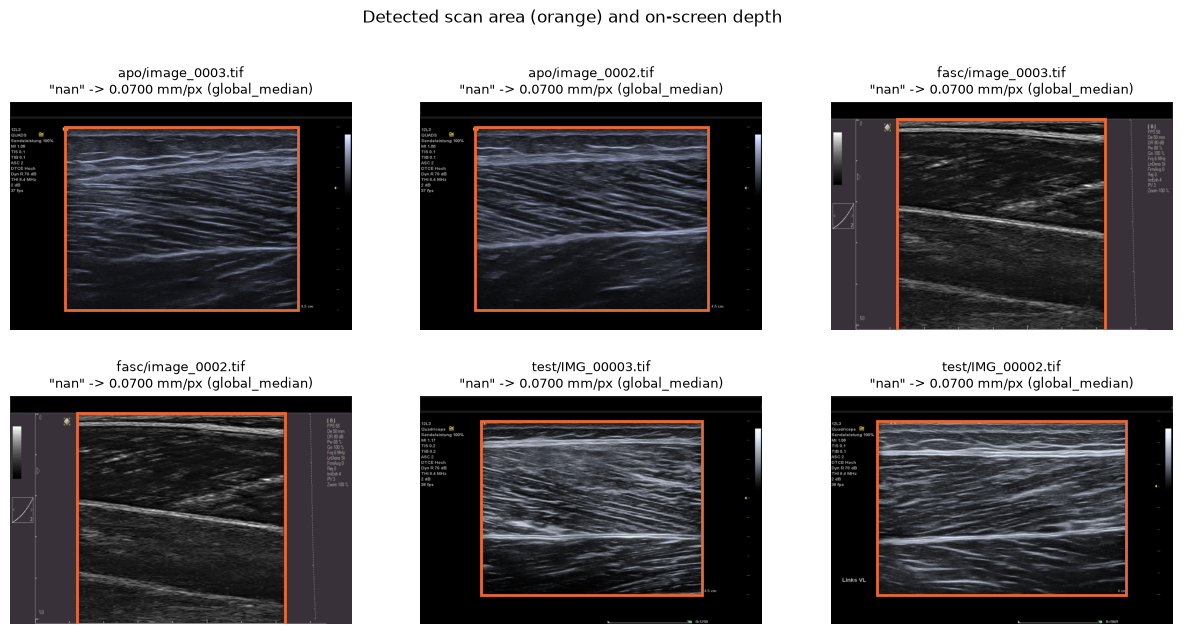

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
picks = pd.concat([scale[scale.set == s].sample(min(2, (scale.set == s).sum()), random_state=1)
                   for s in ['apo', 'fasc', 'test']])
for ax, r in zip(axes.ravel(), picks.itertuples()):
    rgb = read_rgb(all_df.set_index('key').loc[r.key, 'img'])
    ax.imshow(rgb); ax.add_patch(plt.Rectangle((r.fx, r.fy), r.fw, r.fh, fill=False, ec=ORANGE, lw=2))
    ax.set_title(f'{r.set}/{r.name}\n"{r.depth_text}" -> {r.mm_per_px:.4f} mm/px ({r.scale_source})', fontsize=9)
    ax.axis('off')
fig.suptitle('Detected scan area (orange) and on-screen depth', y=1.0)
show(fig, 'fov_check')

## 3. Step 1: resample to a common pixel spacing, then pad
Every scan area is cropped and resampled so that **one canvas pixel is the same number of mm in every image**,
then centred on a square canvas of `P_MM` x `P_MM` (zero padding). `P_MM` covers the 99th percentile of
scan-area extents. The grid's "size" therefore sets the resolution: `spacing = P_MM / size`.
Everything is first cached once at the largest size; smaller sizes and CLAHE are derived from that cache.

canvas covers 65 mm; spacing per grid size: {64: 1.0156, 96: 0.6771} mm/px
cached 15 images at base size 96 in 0.0 min


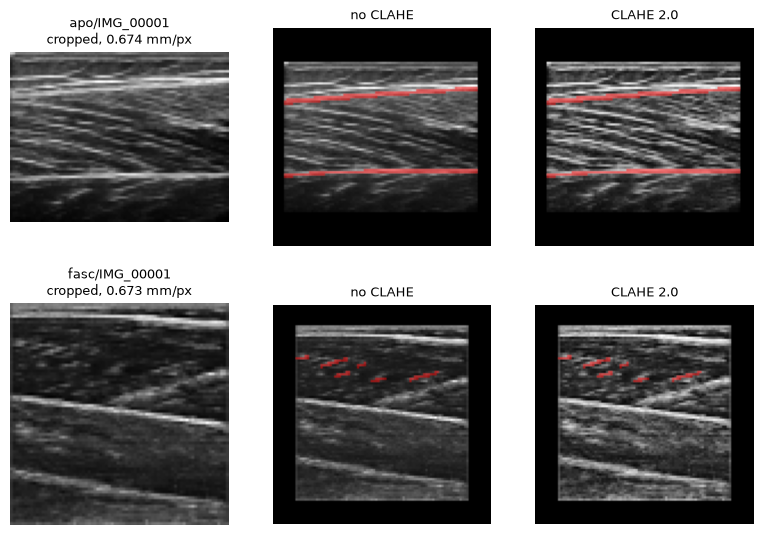

In [31]:
all_df = all_df.merge(scale[['key', 'fx', 'fy', 'fw', 'fh', 'mm_per_px', 'scale_source', 'thash']], on='key')
ext_mm = np.maximum(all_df.fw, all_df.fh) * all_df.mm_per_px
P_MM = float(np.clip(math.ceil(np.percentile(ext_mm, 99) / 5) * 5, 30, 150))
BASE = max(CFG['sizes'])
BASE_SP = P_MM / BASE
print(f'canvas covers {P_MM:.0f} mm; spacing per grid size:',
      {s: round(P_MM / s, 4) for s in CFG['sizes']}, 'mm/px')

def load_base(r):
    g = cv2.cvtColor(read_rgb(r.img), cv2.COLOR_RGB2GRAY)
    x, y, w, h = int(r.fx), int(r.fy), int(r.fw), int(r.fh)
    crop = g[y:y + h, x:x + w]
    f = min(r.mm_per_px / BASE_SP, BASE / w, BASE / h)      # never larger than the canvas
    nw, nh = max(8, round(w * f)), max(8, round(h * f))
    img = cv2.resize(crop, (nw, nh), interpolation=cv2.INTER_AREA if f < 1 else cv2.INTER_LINEAR)
    m = None
    if isinstance(r.mask, str):
        mk = read_mask(r.mask, g.shape, CFG['fasc_dilate_px'] if r.set == 'fasc' else 0)[y:y + h, x:x + w]
        m = (cv2.resize(mk.astype(np.float32), (nw, nh), interpolation=cv2.INTER_AREA) * 255).astype(np.uint8)
    return r.key, (img, m, r.mm_per_px * w / nw)

t0 = time.time()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    BASE_CACHE = dict(ex.map(load_base, all_df.itertuples()))
print(f'cached {len(BASE_CACHE)} images at base size {BASE} in {(time.time() - t0) / 60:.1f} min')

def apply_clahe(img, clip):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(img) if clip > 0 else img

def canvas_meta(base_shape, sp, size):
    h0, w0 = base_shape
    r = size / BASE
    nw, nh = max(4, round(w0 * r)), max(4, round(h0 * r))
    return dict(spacing=sp * w0 / nw, valid=((size - nw) // 2, (size - nh) // 2, nw, nh))

def to_canvas(img, m, sp, size, clip):
    meta = canvas_meta(img.shape, sp, size)
    ox, oy, nw, nh = meta['valid']
    X = np.zeros((size, size), np.uint8)
    X[oy:oy + nh, ox:ox + nw] = cv2.resize(apply_clahe(img, clip), (nw, nh), interpolation=cv2.INTER_AREA)
    Y = None
    if m is not None:
        Y = np.zeros((size, size), np.uint8)
        Y[oy:oy + nh, ox:ox + nw] = cv2.resize(m, (nw, nh), interpolation=cv2.INTER_AREA) > 50   # keep thin lines
    return X, Y, meta

def build_arrays(df, size, clip, with_mask=True):
    N = len(df)
    X = np.zeros((N, size, size), np.uint8)
    Y = np.zeros((N, size, size), np.uint8) if with_mask else None
    metas = []
    for i, k in enumerate(df.key):
        img, m, sp = BASE_CACHE[k]
        x, y, meta = to_canvas(img, m if with_mask else None, sp, size, clip)
        X[i] = x
        if with_mask:
            Y[i] = y
        metas.append(meta)
    return X, Y, metas

fig, axes = plt.subplots(2, 1 + len(CFG['clahe_clips']), figsize=(3.2 * (1 + len(CFG['clahe_clips'])), 6.6))
for row, key in zip(axes, [apo_df.key.iloc[0], fasc_df.key.iloc[0]]):
    img, m, sp = BASE_CACHE[key]
    row[0].imshow(img, cmap='gray'); row[0].set_title(f'{key}\ncropped, {sp:.3f} mm/px', fontsize=9)
    for ax, clip in zip(row[1:], CFG['clahe_clips']):
        X, Y, meta = to_canvas(img, m, sp, BASE, clip)
        ax.imshow(X, cmap='gray'); ax.imshow(np.ma.masked_where(Y == 0, Y), cmap='autumn', alpha=.5)
        ax.set_title(f'CLAHE {clip}' if clip else 'no CLAHE', fontsize=9)
for ax in axes.ravel():
    ax.axis('off')
show(fig, 'preprocessing_examples')

## 4. Splits
A **hold-out set** (15 % of groups) is kept aside for the final metrics table. All grid searches run on the rest.
If an image is in both training sets, it lands on the same side of the split in both.

In [32]:
def holdout_split(df, frac, seed, force=None):
    df = df.copy()
    gss = GroupShuffleSplit(n_splits=1, test_size=frac, random_state=seed)
    _, ho = next(gss.split(df, groups=df.group))
    df['holdout'] = False
    df.loc[df.index[ho], 'holdout'] = True
    if force is not None:                       # thash -> bool, for images shared with the other set
        f = df.key.map(all_df.set_index('key').thash).map(force)
        df.loc[f.notna(), 'holdout'] = f[f.notna()].astype(bool)
    return df

apo_df = holdout_split(apo_df, CFG['holdout_frac'], CFG['seed'])
apo_force = dict(zip(apo_df.key.map(all_df.set_index('key').thash), apo_df.holdout))
fasc_df = holdout_split(fasc_df, CFG['holdout_frac'], CFG['seed'], force=apo_force)
SETS = {'apo': apo_df, 'fasc': fasc_df}
for k, d in SETS.items():
    print(f'{k}: {(~d.holdout).sum()} train, {d.holdout.sum()} hold-out images')

def subsample(df, frac, seed):
    g = df.group.unique()
    k = min(len(g), max(CFG['n_folds'], int(round(len(g) * frac))))
    keep = np.random.default_rng(seed).choice(g, k, replace=False)
    return df[df.group.isin(keep)]

apo: 4 train, 1 hold-out images
fasc: 4 train, 1 hold-out images


## 5. Models, augmentation, training loop
* **Segmentation:** U-Net with a ResNet-34 encoder (ImageNet weights if they can be downloaded), BCE + Dice loss,
  scored by Dice.
* **Regression (Part B):** ResNet-34 -> 3 outputs (PA, FL, MT), Huber loss on standardised targets.
* **Augmentation** (training only, on the GPU): horizontal flip, contrast/brightness/gamma jitter, speckle and
  Gaussian noise. No scaling, because the pixel spacing carries the mm information.
* AdamW, learning rate halves when validation stalls, early stopping on the validation score.

In [33]:
_PRE = {'ok': None}
def resnet34():
    if _PRE['ok'] is not False:
        try:
            m = torchvision.models.resnet34(weights='IMAGENET1K_V1'); _PRE['ok'] = True
            return m
        except Exception as e:
            _PRE['ok'] = False
            print('ImageNet weights unavailable (', type(e).__name__, ') -> training from random init')
    return torchvision.models.resnet34(weights=None)

class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class _Norm(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer('mean', torch.tensor([.485, .456, .406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([.229, .224, .225]).view(1, 3, 1, 1))
    def forward(self, x):                        # grayscale [0,1] -> 3-channel ImageNet-normalised
        return (x.expand(-1, 3, -1, -1) - self.mean) / self.std

class UNetR34(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm, self.enc = _Norm(), resnet34()
        self.enc.fc = nn.Identity()
        self.dec = nn.ModuleList([ConvBlock(512 + 256, 256), ConvBlock(256 + 128, 128), ConvBlock(128 + 64, 64),
                                  ConvBlock(64 + 64, 32), ConvBlock(32, 16)])
        self.head = nn.Conv2d(16, 1, 1)
    def forward(self, x):
        e = self.enc
        s0 = e.relu(e.bn1(e.conv1(self.norm(x))))     # 1/2
        s1 = e.layer1(e.maxpool(s0))                  # 1/4
        s2 = e.layer2(s1); s3 = e.layer3(s2); d = e.layer4(s3)
        for blk, skip in zip(self.dec[:4], [s3, s2, s1, s0]):
            d = blk(torch.cat([F.interpolate(d, size=skip.shape[-2:], mode='bilinear', align_corners=False), skip], 1))
        d = self.dec[4](F.interpolate(d, scale_factor=2, mode='bilinear', align_corners=False))
        return self.head(d)

class RegR34(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm, self.enc = _Norm(), resnet34()
        self.enc.fc = nn.Identity()
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(512, 3))
    def forward(self, x):
        return self.head(self.enc(self.norm(x)))

class TargetNorm:
    """Standardise [PA, FL, MT]; optionally log-transform FL first."""
    def __init__(self, Y, log_fl):
        self.log_fl = bool(log_fl)
        Z = self._fwd(Y)
        self.mu, self.sd, self.raw_sd = Z.mean(0), Z.std(0) + 1e-6, Y.std(0) + 1e-6
    def _fwd(self, Y):
        Z = np.asarray(Y, np.float64).copy()
        if self.log_fl:
            Z[:, 1] = np.log(Z[:, 1])
        return Z
    def encode(self, Y):
        return ((self._fwd(Y) - self.mu) / self.sd).astype(np.float32)
    def decode(self, Z):
        Y = np.asarray(Z, np.float64) * self.sd + self.mu
        if self.log_fl:
            Y[:, 1] = np.exp(Y[:, 1])
        return Y

class ArrDS(Dataset):
    def __init__(self, X, Y):
        self.X, self.Y = X, Y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        y = torch.from_numpy(np.asarray(self.Y[i]))
        return torch.from_numpy(self.X[i])[None], (y[None] if y.ndim == 2 else y)

def augment(x, y, seg):
    B, dev = x.shape[0], x.device
    flip = (torch.rand(B, device=dev) < 0.5)[:, None, None, None]
    x = torch.where(flip, x.flip(-1), x)
    if seg:
        y = torch.where(flip, y.flip(-1), y)
    valid = (x > 0).float()                        # keep the zero padding at zero
    r = lambda: torch.rand(B, 1, 1, 1, device=dev)
    x = ((x - .5) * (1 + (r() - .5) * .5) + .5 + (r() - .5) * .2).clamp(1e-4, 1)
    x = x ** torch.exp((r() - .5) * .6)
    x = x * (1 + .15 * torch.randn_like(x) * (r() < .5).float())          # multiplicative (speckle-like) noise
    x = (x + .02 * torch.randn_like(x)).clamp(0, 1)
    return x * valid, y

def seg_loss(logits, y):
    bce = F.binary_cross_entropy_with_logits(logits, y)
    p = torch.sigmoid(logits)
    dice = 1 - (2 * (p * y).sum((1, 2, 3)) + 1) / (p.sum((1, 2, 3)) + y.sum((1, 2, 3)) + 1)
    return bce + dice.mean()

@torch.no_grad()
def dice_iou(logits, y, thr=0.5):
    p = (torch.sigmoid(logits) > thr).float()
    inter = (p * y).sum((1, 2, 3)); ps, ys = p.sum((1, 2, 3)), y.sum((1, 2, 3))
    one = torch.ones_like(inter)
    dice = torch.where(ps + ys > 0, 2 * inter / (ps + ys).clamp_min(1), one)
    iou = torch.where(ps + ys - inter > 0, inter / (ps + ys - inter).clamp_min(1), one)
    return dice, iou

def _loader(X, Y, batch, shuffle):
    return DataLoader(ArrDS(X, Y), batch_size=batch, shuffle=shuffle, drop_last=shuffle and len(X) > batch,
                      num_workers=CFG['num_workers'], pin_memory=AMP)

@torch.no_grad()
def _val_score(model, dl, kind, tn):
    model.eval(); ds, P, T = [], [], []
    for x, y in dl:
        x = x.to(DEVICE).float() / 255
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            o = model(x)
        if kind == 'seg':
            ds.append(dice_iou(o.float(), y.to(DEVICE).float())[0].cpu())
        else:
            P.append(o.float().cpu().numpy()); T.append(y.numpy())
    if kind == 'seg':
        return torch.cat(ds).mean().item()
    P, T = tn.decode(np.concatenate(P)), np.concatenate(T)
    return -float(np.mean(np.abs(P - T).mean(0) / tn.raw_sd))        # minus the scale-free MAE (higher = better)

def fit(kind, Xtr, Ytr, Xva, Yva, *, epochs, patience, batch, lr, log_fl=False, tag=''):
    """kind='seg': Y are masks, score = Dice.  kind='reg': Y are raw [PA, FL, MT], score = -MAE/sd."""
    seed_all(CFG['seed'])
    model = (UNetR34() if kind == 'seg' else RegR34()).to(DEVICE)
    tn = TargetNorm(Ytr, log_fl) if kind == 'reg' else None
    dl_tr = _loader(Xtr, tn.encode(Ytr) if tn else Ytr, batch, True)
    dl_va = _loader(Xva, Yva.astype(np.float32) if tn else Yva, max(batch, 16), False)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=max(2, patience // 3))
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    best, best_ep, best_state, wait, hist = -np.inf, 0, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE, non_blocking=True).float() / 255, y.to(DEVICE, non_blocking=True).float()
            x, y = augment(x, y, kind == 'seg')
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
                out = model(x)
            loss = seg_loss(out.float(), y) if kind == 'seg' else F.smooth_l1_loss(out.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(x); n += len(x)
        score = _val_score(model, dl_va, kind, tn)
        sched.step(score)
        hist.append(dict(epoch=ep, train_loss=tot / max(n, 1), val_score=score, lr=opt.param_groups[0]['lr']))
        if score > best + 1e-4:
            best, best_ep, wait = score, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if wait >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, tn, dict(best_score=best, best_epoch=best_ep, epochs_run=len(hist)), pd.DataFrame(hist)

@torch.no_grad()
def predict(model, X, batch=16, tta=True):
    """Segmentation: (N, S, S) probabilities.  Regression: (N, 3) standardised outputs. Flip TTA."""
    model.eval(); outs = []
    if len(X) == 0:
        return np.zeros((0, 3) if isinstance(model, RegR34) else (0,) + X.shape[1:], np.float32)
    for i in range(0, len(X), batch):
        x = torch.from_numpy(X[i:i + batch])[:, None].to(DEVICE).float() / 255
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            o = model(x).float()
            if tta:
                o2 = model(x.flip(-1)).float()
                o = (o + (o2.flip(-1) if o.ndim == 4 else o2)) / 2
        outs.append((torch.sigmoid(o)[:, 0] if o.ndim == 4 else o).cpu().numpy())
    return np.concatenate(outs)

def run_cv(name, configs, data_fn, fit_kw, csv):
    """Grouped k-fold CV over a list of configs. Results are appended to `csv` after each fold (resumable)."""
    rows = pd.read_csv(csv).to_dict('records') if csv.exists() else []
    done = {(r['cfg'], int(r['fold'])) for r in rows}
    for c in configs:
        todo = [f for f in range(CFG['n_folds']) if (c['cfg'], f) not in done]
        if not todo:
            continue
        X, Y, groups = data_fn(c)
        folds = list(GroupKFold(n_splits=CFG['n_folds']).split(X, groups=groups))
        for f in todo:
            tr, va = folds[f]
            t0 = time.time()
            _, _, res, _ = fit(c.get('kind', 'seg'), X[tr], Y[tr], X[va], Y[va], **fit_kw(c))
            rows.append({**c, 'fold': f, **res, 'minutes': (time.time() - t0) / 60})
            pd.DataFrame(rows).to_csv(csv, index=False)
            print(f'[{name}] {c["cfg"]} fold {f}: score {res["best_score"]:.4f} '
                  f'(best epoch {res["best_epoch"]}/{res["epochs_run"]}, {rows[-1]["minutes"]:.1f} min)')
        del X, Y
    res = pd.DataFrame(rows)
    summ = (res.groupby('cfg').agg(score_mean=('best_score', 'mean'), score_sd=('best_score', 'std'),
                                   best_epoch=('best_epoch', 'median'), minutes=('minutes', 'sum'))
            .sort_values('score_mean', ascending=False))
    return res, summ

def heat(ax, pv, title, fmt='{:.3f}'):
    im = ax.imshow(pv.values, cmap=SEQ, aspect='auto')
    ax.set_xticks(range(pv.shape[1]), [str(c) for c in pv.columns]); ax.set_yticks(range(pv.shape[0]), [str(i) for i in pv.index])
    ax.set_xlabel(pv.columns.name); ax.set_ylabel(pv.index.name); ax.set_title(title); ax.grid(False)
    lo, hi = np.nanmin(pv.values), np.nanmax(pv.values)
    for (i, j), v in np.ndenumerate(pv.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=9,
                    color='white' if hi > lo and (v - lo) / (hi - lo) > .55 else '#0b0b0b')
    plt.colorbar(im, ax=ax, fraction=.046)

n2 = len(CFG['sizes']) * len(CFG['clahe_clips']) * CFG['n_folds'] * 2
n3 = len(CFG['batch_sizes']) * len(CFG['lrs']) * CFG['n_folds'] * 2
print(f'Part A training runs: step 2 = {n2} (subsample), step 3 = {n3} (full set), step 4 = 2 final models')

Part A training runs: step 2 = 16 (subsample), step 3 = 8 (full set), step 4 = 2 final models


## 6. Step 2: grid search of input size x CLAHE contrast (5-fold CV, subsample)
Each configuration is scored by mean validation Dice, separately for the aponeurosis and the fascicle model
(each model may prefer different settings). *Log-transforming the length output only applies to a model that
outputs lengths directly, so it is tested in Part B (§11).*

--- apo: 4 images in the subsample, 4 configs ---
--- fasc: 4 images in the subsample, 4 configs ---
apo: best = size 64 (1.016 mm/px), CLAHE 0.0  | Dice 0.1675 +/- 0.0124
fasc: best = size 96 (0.677 mm/px), CLAHE 2.0  | Dice 0.0357 +/- 0.0116


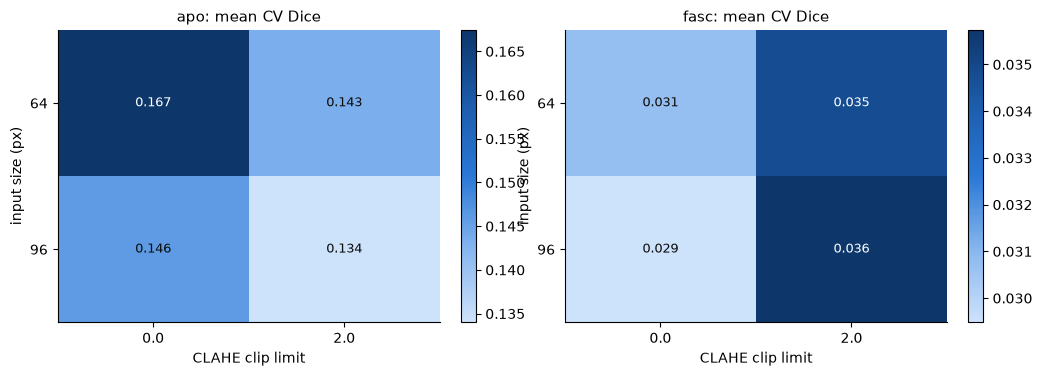

In [34]:
def seg_data(df):
    def fn(c):
        X, Y, _ = build_arrays(df, c['size'], c['clip'])
        return X, Y, df.group.values
    return fn

step2 = {}
for kind in ['apo', 'fasc']:
    sub = subsample(SETS[kind][~SETS[kind].holdout], CFG['subsample_frac'], CFG['seed'])
    configs = [dict(cfg=f's{s}_c{c}', size=s, clip=c, kind='seg') for s in CFG['sizes'] for c in CFG['clahe_clips']]
    print(f'--- {kind}: {len(sub)} images in the subsample, {len(configs)} configs ---')
    step2[kind] = run_cv(f'step2-{kind}', configs, seg_data(sub),
                         lambda c: dict(epochs=CFG['step2_epochs'], patience=CFG['step2_patience'],
                                        batch=CFG['step2_batch'], lr=CFG['step2_lr']),
                         OUT / f'step2_{kind}.csv')

BEST = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, kind in zip(axes, ['apo', 'fasc']):
    res, summ = step2[kind]
    pv = res.groupby(['size', 'clip']).best_score.mean().unstack()
    pv.index.name, pv.columns.name = 'input size (px)', 'CLAHE clip limit'
    heat(ax, pv, f'{kind}: mean CV Dice')
    top = res[res.cfg == summ.index[0]].iloc[0]
    BEST[kind] = dict(size=int(top['size']), clip=float(top['clip']))
    print(f'{kind}: best = size {BEST[kind]["size"]} ({P_MM / BEST[kind]["size"]:.3f} mm/px), '
          f'CLAHE {BEST[kind]["clip"]}  | Dice {summ.score_mean.iloc[0]:.4f} +/- {summ.score_sd.iloc[0]:.4f}')
show(fig, 'step2_heatmaps')

## 7. Step 3: grid search of batch size x learning rate (5-fold CV, full training set)

--- apo: 4 images, 2 configs ---
apo: best = batch 2, lr 0.001 | Dice 0.1875
--- fasc: 4 images, 2 configs ---
fasc: best = batch 2, lr 0.001 | Dice 0.0382


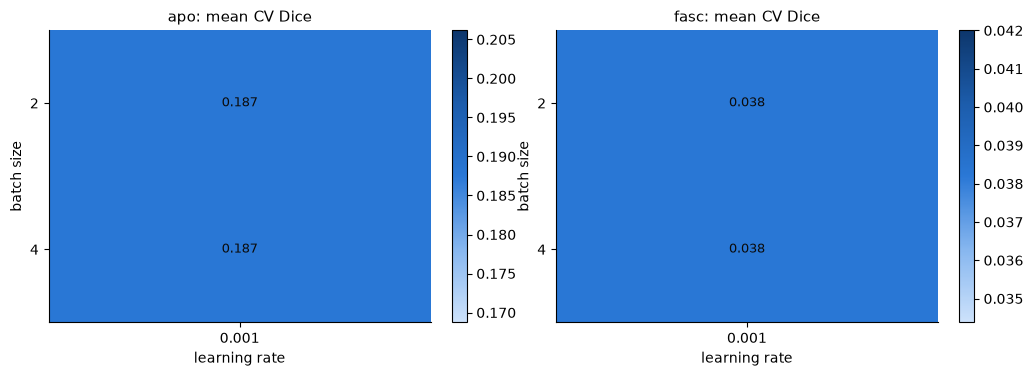

In [35]:
step3 = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, kind in zip(axes, ['apo', 'fasc']):
    tr = SETS[kind][~SETS[kind].holdout]
    configs = [dict(cfg=f'b{b}_lr{lr:g}', batch=b, lr=lr, kind='seg', **BEST[kind])
               for b in CFG['batch_sizes'] for lr in CFG['lrs']]
    print(f'--- {kind}: {len(tr)} images, {len(configs)} configs ---')
    cache = {}
    def data_fn(c, tr=tr, cache=cache):
        if 'X' not in cache:
            cache['X'], cache['Y'], _ = build_arrays(tr, c['size'], c['clip'])
        return cache['X'], cache['Y'], tr.group.values
    step3[kind] = run_cv(f'step3-{kind}', configs, data_fn,
                         lambda c: dict(epochs=CFG['step3_epochs'], patience=CFG['step3_patience'],
                                        batch=c['batch'], lr=c['lr']),
                         OUT / f'step3_{kind}.csv')
    cache.clear()
    res, summ = step3[kind]
    pv = res.groupby(['batch', 'lr']).best_score.mean().unstack()
    pv.index.name, pv.columns.name = 'batch size', 'learning rate'
    heat(ax, pv, f'{kind}: mean CV Dice')
    top = res[res.cfg == summ.index[0]].iloc[0]
    BEST[kind].update(batch=int(top['batch']), lr=float(top['lr']))
    print(f'{kind}: best = batch {BEST[kind]["batch"]}, lr {BEST[kind]["lr"]:g} | Dice {summ.score_mean.iloc[0]:.4f}')
show(fig, 'step3_heatmaps')
pd.DataFrame(BEST).T.to_csv(OUT / 'best_configs_A.csv')

## 8. Step 4: final segmentation models (up to 200 epochs)
Trained on all non-hold-out images; 10 % of their groups are used only for early stopping.

apo: Dice 0.2164 at epoch 3 (0.0 min)
fasc: Dice 0.0390 at epoch 2 (0.0 min)


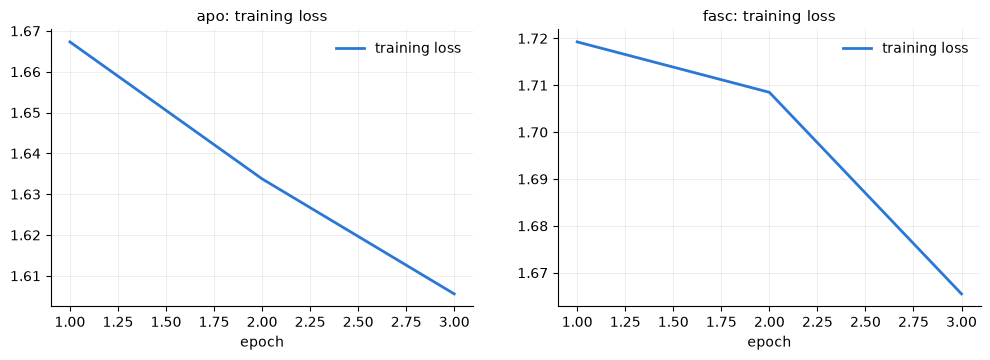

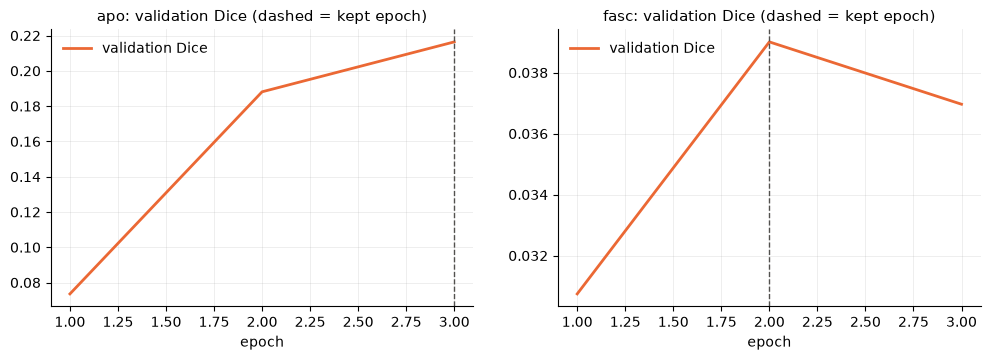

In [36]:
def internal_split(df, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=seed)
    return next(gss.split(df, groups=df.group))

MODELS, HIST = {}, {}
for kind in ['apo', 'fasc']:
    path, c = OUT / f'final_{kind}.pt', BEST[kind]
    if CFG['reuse_saved'] and path.exists():
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        if ck['cfg'] == c:
            m = UNetR34().to(DEVICE); m.load_state_dict(ck['state']); MODELS[kind] = m.eval()
            HIST[kind] = pd.DataFrame(ck['hist']); print(f'{kind}: loaded {path}')
            continue
    tr = SETS[kind][~SETS[kind].holdout]
    X, Y, _ = build_arrays(tr, c['size'], c['clip'])
    a, b = internal_split(tr, CFG['seed'])
    t0 = time.time()
    m, _, res, hist = fit('seg', X[a], Y[a], X[b], Y[b], epochs=CFG['final_epochs'], patience=CFG['final_patience'],
                          batch=c['batch'], lr=c['lr'])
    MODELS[kind], HIST[kind] = m.eval(), hist
    torch.save(dict(state=m.state_dict(), cfg=c, hist=hist.to_dict('list')), path)
    print(f'{kind}: Dice {res["best_score"]:.4f} at epoch {res["best_epoch"]} ({(time.time() - t0) / 60:.1f} min)')
    del X, Y

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, kind in zip(axes, ['apo', 'fasc']):
    h = HIST[kind]
    ax.plot(h.epoch, h.train_loss, color=BLUE, label='training loss')
    ax.set_title(f'{kind}: training loss'); ax.set_xlabel('epoch'); ax.legend(frameon=False)
show(fig, 'final_training_loss')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, kind in zip(axes, ['apo', 'fasc']):
    h = HIST[kind]
    ax.plot(h.epoch, h.val_score, color=ORANGE, label='validation Dice')
    ax.axvline(h.epoch[h.val_score.idxmax()], color=INK, lw=1, ls='--')
    ax.set_title(f'{kind}: validation Dice (dashed = kept epoch)'); ax.set_xlabel('epoch'); ax.legend(frameon=False)
show(fig, 'final_validation_dice')

## 9. Masks -> numbers, metrics table and submission (Part A)
**Geometry** (works on a common canvas so that both masks line up):
* **Aponeuroses:** connected pieces of the mask lying on the same band are merged; the two longest bands are the
  superficial (upper) and deep (lower) aponeurosis. The *inner* edges (bottom of the superficial, top of the deep
  band) are fitted with a 2nd-order polynomial, extended as straight lines beyond the mask.
* **MT:** perpendicular distance between the inner edges at 25 / 50 / 75 % of their overlap, averaged
  (the organisers measured at three locations).
* **Fascicles:** each piece between the aponeuroses gets a straight line. PA = angle to the deep aponeurosis at the
  crossing point; FL = distance between the two crossings (straight-line extrapolation beyond the image, as the
  annotators did). Pieces pointing against the dominant direction or outside plausible ranges are dropped; the
  image value is the length-weighted median.

A unit test on a drawn image with known values runs first.

In [37]:
class Curve:
    """y(x): polynomial inside the fitted range, straight-line extension outside."""
    def __init__(self, xs, ys, deg):
        self.x0, self.x1 = float(np.min(xs)), float(np.max(xs))
        self.p = np.polyfit(xs, ys, deg); self.dp = np.polyder(self.p)
    def __call__(self, x):
        x = np.asarray(x, float); xc = np.clip(x, self.x0, self.x1)
        return np.polyval(self.p, xc) + np.polyval(self.dp, xc) * (x - xc)
    def slope(self, x):
        return np.polyval(self.dp, np.clip(x, self.x0, self.x1))

def apo_curves(prob, thr, valid):
    ox, oy, vw, vh = valid
    n, lab, st, _ = cv2.connectedComponentsWithStats((prob > thr).astype(np.uint8), 8)
    comps = sorted([i for i in range(1, n) if st[i, cv2.CC_STAT_WIDTH] >= 0.08 * vw and st[i, cv2.CC_STAT_AREA] >= 15],
                   key=lambda i: -st[i, cv2.CC_STAT_WIDTH])
    groups = []
    for i in comps:
        ys, xs = np.nonzero(lab == i)
        for g in groups:                                     # same band as an existing group?
            if np.median(np.abs(g['curve'](xs) - ys)) < 0.04 * vh:
                g['xs'], g['ys'] = np.r_[g['xs'], xs], np.r_[g['ys'], ys]
                g['curve'] = Curve(g['xs'], g['ys'], 1)
                break
        else:
            groups.append(dict(xs=xs, ys=ys, curve=Curve(xs, ys, 1)))
    groups = sorted(groups, key=lambda g: -np.ptp(g['xs']))[:2]
    if len(groups) < 2:
        return None
    sup, deep = sorted(groups, key=lambda g: g['ys'].mean())
    def edge(g, how):
        e = pd.DataFrame({'x': g['xs'], 'y': g['ys']}).groupby('x').y.agg(how)
        x, y = e.index.values.astype(float), e.values.astype(float)
        return Curve(x, y, 2 if np.ptp(x) > 0.3 * vw else 1)
    return edge(sup, 'max'), edge(deep, 'min')

def _dense(curve, valid, n=4000):
    ox, oy, vw, vh = valid
    xs = np.linspace(ox - 2 * vw, ox + 3 * vw, n)
    return np.c_[xs, curve(xs)]

def thickness_px(sup, deep, valid):
    ox, oy, vw, vh = valid
    lo, hi = max(sup.x0, deep.x0, ox), min(sup.x1, deep.x1, ox + vw)
    if hi - lo < 0.2 * vw:                       # little overlap: measure on the extended lines
        lo, hi = ox + 0.2 * vw, ox + 0.8 * vw
    pts = _dense(sup, valid)
    d = [np.min(np.hypot(pts[:, 0] - x, pts[:, 1] - deep(x))) for x in lo + (hi - lo) * np.array([.25, .5, .75])]
    return float(np.mean(d))

def _intersect(l, curve, valid):
    ox, oy, vw, vh = valid
    m = l['vy'] / l['vx']
    xs = np.linspace(l['x0'] - 6 * vw, l['x0'] + 6 * vw, 12001)
    f = l['y0'] + m * (xs - l['x0']) - curve(xs)
    s = np.nonzero(np.diff(np.sign(f)))[0]
    if len(s) == 0:
        return None
    k = s[np.argmin(np.abs(xs[s] - l['x0']))]
    x = xs[k] - f[k] * (xs[k + 1] - xs[k]) / (f[k + 1] - f[k])
    return np.array([x, float(curve(x))])

def wmedian(v, w):
    o = np.argsort(v); v, w = np.asarray(v)[o], np.asarray(w)[o]
    return float(v[np.searchsorted(np.cumsum(w), 0.5 * w.sum())])

def analyze(apo_prob, fasc_prob, spacing, valid, thr_apo=None, thr_fasc=None):
    thr_apo = CFG['thr_apo'] if thr_apo is None else thr_apo
    thr_fasc = CFG['thr_fasc'] if thr_fasc is None else thr_fasc
    out = dict(pa_deg=np.nan, fl_mm=np.nan, mt_mm=np.nan, n_fasc=0, apo_ok=False, sup=None, deep=None, lines=[])
    ox, oy, vw, vh = valid
    inside = np.zeros(apo_prob.shape, bool); inside[oy:oy + vh, ox:ox + vw] = True   # ignore the zero padding
    apo_prob = np.where(inside, apo_prob, 0)
    if fasc_prob is not None:
        fasc_prob = np.where(inside, fasc_prob, 0)
    ap = apo_curves(apo_prob, thr_apo, valid)
    if ap is None:
        return out
    sup, deep = ap
    out.update(apo_ok=True, sup=sup, deep=deep, mt_mm=thickness_px(sup, deep, valid) * spacing)
    if fasc_prob is None:
        return out
    H, W = fasc_prob.shape
    cols = np.arange(W)
    rows = np.arange(H)[:, None]
    between = (rows > sup(cols)[None, :]) & (rows < deep(cols)[None, :])
    m = ((fasc_prob > thr_fasc) & between).astype(np.uint8)
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, 8)
    min_px = max(8, int(0.0003 * H * W))
    cand = []
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] < min_px:
            continue
        ys, xs = np.nonzero(lab == i)
        if np.ptp(xs) < 5:
            continue
        vx, vy, x0, y0 = cv2.fitLine(np.c_[xs, ys].astype(np.float32), cv2.DIST_L2, 0, .01, .01).ravel()
        if abs(vx) < 1e-3:
            continue
        l = dict(vx=float(vx), vy=float(vy), x0=float(x0), y0=float(y0), w=float(np.hypot(np.ptp(xs), np.ptp(ys))))
        ps, pd_ = _intersect(l, sup, valid), _intersect(l, deep, valid)
        if ps is None or pd_ is None:
            continue
        u = np.array([vx, vy]) / np.hypot(vx, vy)
        t = np.array([1.0, deep.slope(pd_[0])]); t /= np.linalg.norm(t)
        pa = float(np.degrees(np.arccos(min(1.0, abs(u @ t)))))
        side = np.sign((ps - pd_)[0])                 # fascicle leans left or right going up
        fl = float(np.hypot(*(ps - pd_)) * spacing)
        if 2 <= pa <= 60 and 10 <= fl <= 300:
            cand.append(dict(l, ps=ps, pd=pd_, pa=pa, fl=fl, side=side))
    if cand:
        sides = pd.DataFrame(cand).groupby('side').w.sum()
        cand = [c for c in cand if c['side'] == sides.idxmax()]
        pa_med = wmedian([c['pa'] for c in cand], [c['w'] for c in cand])
        cand = [c for c in cand if abs(c['pa'] - pa_med) <= 10] or cand
        w = [c['w'] for c in cand]
        out.update(pa_deg=wmedian([c['pa'] for c in cand], w), fl_mm=wmedian([c['fl'] for c in cand], w),
                   n_fasc=len(cand), lines=cand)
    return out

def _unit_test_geometry():
    S, sp = 400, 0.1
    apo, fas = np.zeros((S, S), np.float32), np.zeros((S, S), np.float32)
    xs = np.arange(20, 380)
    s_mid, d_mid = 60 + 0.05 * xs, 300 - 0.02 * xs
    for x, a, b in zip(xs, s_mid, d_mid):
        apo[int(round(a)) - 3:int(round(a)) + 4, x] = 1; apo[int(round(b)) - 3:int(round(b)) + 4, x] = 1
    sup_e = lambda x: 60 + 0.05 * x + 3                  # inner edges
    deep_e = lambda x: 300 - 0.02 * x - 3
    theta = math.radians(18)
    t = np.array([1, -0.02]); t /= np.linalg.norm(t)
    u = np.array([t[0] * math.cos(theta) + t[1] * math.sin(theta), -t[0] * math.sin(theta) + t[1] * math.cos(theta)])
    fls = []
    for x0 in [60, 120, 180]:
        p = np.array([x0, deep_e(x0)])
        k = (sup_e(0) + 0.05 * p[0] - p[1]) / (u[1] - 0.05 * u[0])      # solve p + k u on the superficial edge
        fls.append(k * sp)
        q = p + 0.75 * k * u                                           # draw only 75 %: extrapolation is tested
        cv2.line(fas, tuple(np.round(p - 4 * u).astype(int)), tuple(np.round(q).astype(int)), 1, 3)
    r = analyze(apo, fas, sp, (0, 0, S, S))
    mt_true = np.mean([abs(0.05 * x - deep_e(x) + sup_e(0)) / math.sqrt(1 + 0.05 ** 2) for x in [110, 200, 290]]) * sp
    print(f'unit test  PA {r["pa_deg"]:.2f} (true 18.00) | FL {r["fl_mm"]:.2f} (true {np.median(fls):.2f}) | '
          f'MT {r["mt_mm"]:.2f} (true {mt_true:.2f})')
    assert abs(r['pa_deg'] - 18) < 1.5 and abs(r['fl_mm'] / np.median(fls) - 1) < 0.05 and abs(r['mt_mm'] / mt_true - 1) < 0.03
_unit_test_geometry()

unit test  PA 18.11 (true 18.00) | FL 59.85 (true 60.13) | MT 21.98 (true 21.97)


model  n   Dice  Dice_sd    IoU
  apo  1 0.3292      NaN 0.1971
 fasc  1 0.0304      NaN 0.0154

Part A, hold-out images (MPE = signed mean % error, MAPE = absolute):
parameter  n  failed   MSE  RMSE  MAE  MPE_pct  MAPE_pct  R2
 PA (deg)  0       1   NaN   NaN  NaN      NaN       NaN NaN
  FL (mm)  0       1   NaN   NaN  NaN      NaN       NaN NaN
  MT (mm)  1       0 0.533  0.73 0.73    3.995     3.995 NaN


/opt/anaconda3/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


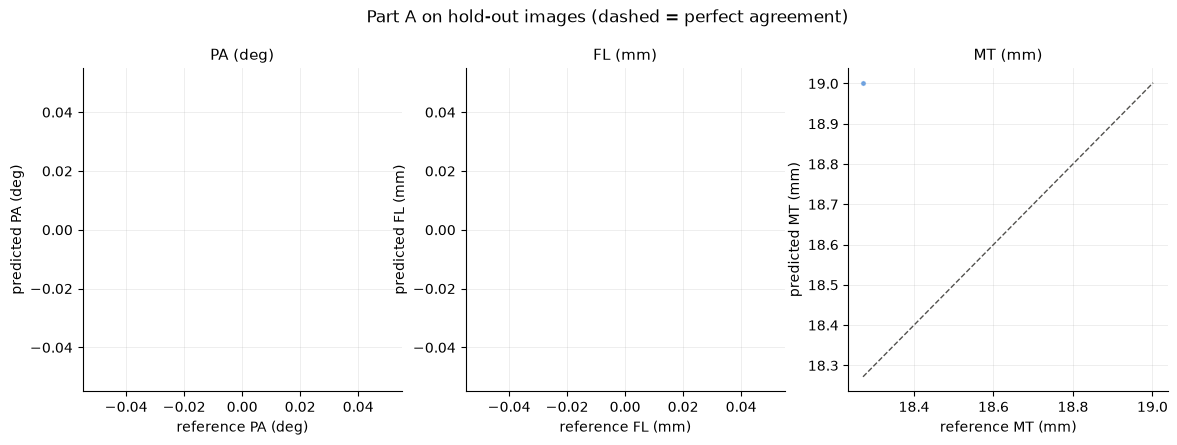


submission_A.csv: 5 rows; filled with the median for {'pa_deg': 3, 'fl_mm': 3, 'mt_mm': 0} images


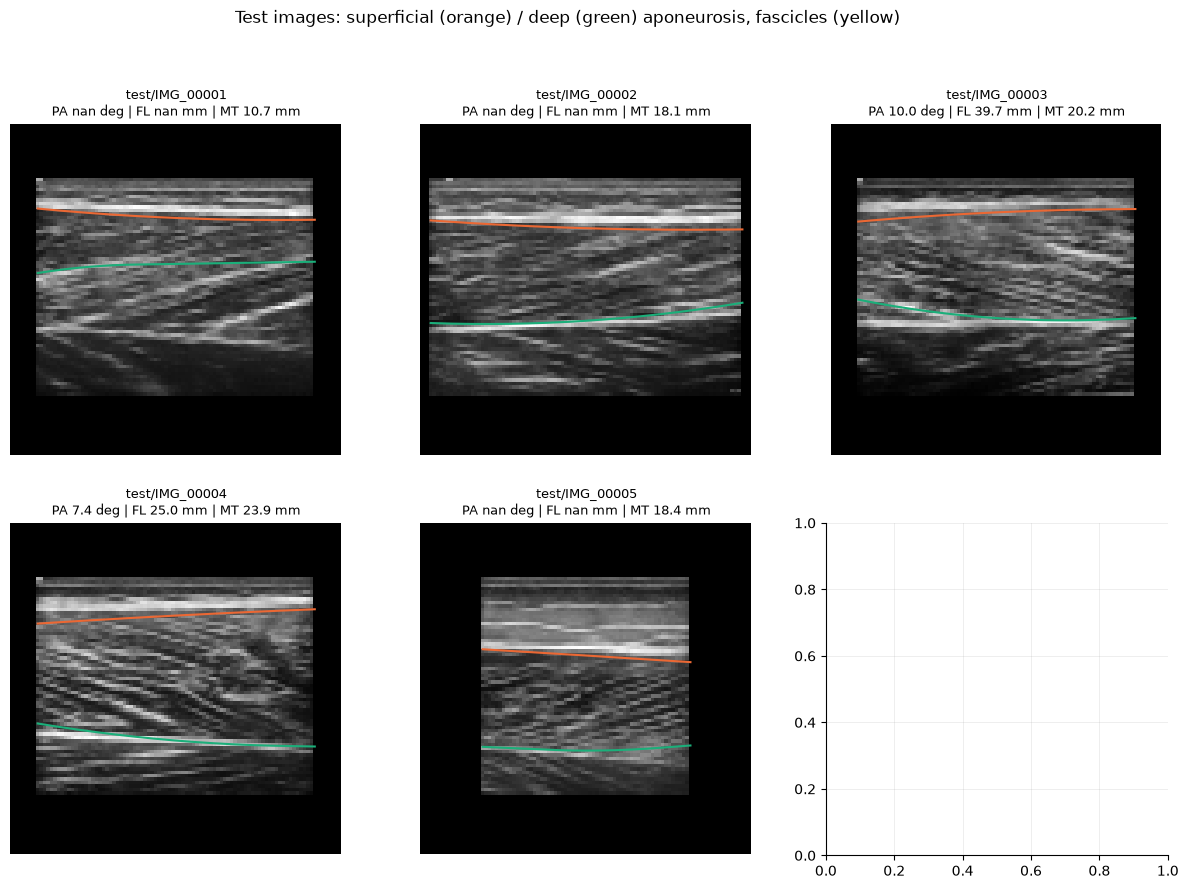

In [38]:
S_GEO = max(BEST['apo']['size'], BEST['fasc']['size'])

def measure_set(df, apo_src, fasc_src, chunk=48, keep=False):
    """PA/FL/MT for every row. *_src = 'gt' (that row's own mask), 'pred' (model) or None."""
    out, kept = [], []
    for s in range(0, len(df), chunk):
        d = df.iloc[s:s + chunk]
        maps = {}
        for kind, src in [('apo', apo_src), ('fasc', fasc_src)]:
            if src == 'gt':
                maps[kind] = build_arrays(d, S_GEO, 0.0)[1].astype(np.float32)
            elif src == 'pred':
                X = build_arrays(d, BEST[kind]['size'], BEST[kind]['clip'], with_mask=False)[0]
                P = predict(MODELS[kind], X)
                maps[kind] = np.stack([cv2.resize(p.astype(np.float32), (S_GEO, S_GEO), interpolation=cv2.INTER_LINEAR)
                                       for p in P])
            else:
                maps[kind] = [None] * len(d)
        for i, k in enumerate(d.key):
            img, _, sp = BASE_CACHE[k]
            meta = canvas_meta(img.shape, sp, S_GEO)
            r = analyze(maps['apo'][i], maps['fasc'][i], meta['spacing'], meta['valid'])
            out.append(dict(key=k, pa_deg=r['pa_deg'], fl_mm=r['fl_mm'], mt_mm=r['mt_mm'], n_fasc=r['n_fasc']))
            if keep:
                kept.append((k, r, maps['apo'][i], maps['fasc'][i]))
    res = pd.DataFrame(out)
    return (res, kept) if keep else res

def reg_metrics(true, pred, name):
    t, p = np.asarray(true, float), np.asarray(pred, float)
    ok = np.isfinite(t) & np.isfinite(p)
    t, p = t[ok], p[ok]
    e = p - t
    return dict(parameter=name, n=int(ok.sum()), failed=int((~ok).sum()), MSE=np.mean(e ** 2),
                RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)), MPE_pct=100 * np.mean(e / t),
                MAPE_pct=100 * np.mean(np.abs(e) / t),
                R2=1 - np.sum(e ** 2) / np.sum((t - t.mean()) ** 2) if len(t) > 1 else np.nan)

# --- segmentation metrics on the hold-out sets
seg_rows = []
for kind in ['apo', 'fasc']:
    ho = SETS[kind][SETS[kind].holdout]
    X, Y, _ = build_arrays(ho, BEST[kind]['size'], BEST[kind]['clip'])
    P = torch.from_numpy(predict(MODELS[kind], X))[:, None]
    logit = torch.logit(P.float().clamp(1e-6, 1 - 1e-6))
    d, iou = dice_iou(logit, torch.from_numpy(Y)[:, None].float())
    seg_rows.append(dict(model=kind, n=len(ho), Dice=d.mean().item(), Dice_sd=d.std().item(), IoU=iou.mean().item()))
seg_table = pd.DataFrame(seg_rows)
print(seg_table.round(4).to_string(index=False))

# --- PA / FL / MT on the hold-out sets
# apo hold-out:  reference MT from the true aponeurosis mask, prediction from the model
# fasc hold-out: reference PA/FL from the true fascicle mask + predicted aponeuroses, prediction from both models
apo_ho, fasc_ho = SETS['apo'][SETS['apo'].holdout], SETS['fasc'][SETS['fasc'].holdout]
ref_apo, pred_apo = measure_set(apo_ho, 'gt', None), measure_set(apo_ho, 'pred', None)
ref_fasc, pred_fasc = measure_set(fasc_ho, 'pred', 'gt'), measure_set(fasc_ho, 'pred', 'pred')
metrics_A = pd.DataFrame([reg_metrics(ref_fasc.pa_deg, pred_fasc.pa_deg, 'PA (deg)'),
                          reg_metrics(ref_fasc.fl_mm, pred_fasc.fl_mm, 'FL (mm)'),
                          reg_metrics(ref_apo.mt_mm, pred_apo.mt_mm, 'MT (mm)')])
metrics_A.to_csv(OUT / 'metrics_A_holdout.csv', index=False)
print('\nPart A, hold-out images (MPE = signed mean % error, MAPE = absolute):')
print(metrics_A.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (ref, pr, col, lab) in zip(axes, [(ref_fasc, pred_fasc, 'pa_deg', 'PA (deg)'), (ref_fasc, pred_fasc, 'fl_mm', 'FL (mm)'),
                                          (ref_apo, pred_apo, 'mt_mm', 'MT (mm)')]):
    ax.scatter(ref[col], pr[col], s=14, color=BLUE, alpha=.7, edgecolor='white', linewidth=.4)
    v = pd.concat([ref[col], pr[col]]).dropna()
    if len(v):
        ax.plot([v.min(), v.max()], [v.min(), v.max()], color=INK, lw=1, ls='--')
    ax.set_xlabel(f'reference {lab}'); ax.set_ylabel(f'predicted {lab}'); ax.set_title(lab)
fig.suptitle('Part A on hold-out images (dashed = perfect agreement)', y=1.02)
show(fig, 'holdout_scatter_A')

# --- test-set predictions
test_A, test_kept = measure_set(test_df, 'pred', 'pred', keep=True)
test_A = test_df[['key', 'name']].merge(test_A, on='key')

def finalize(pred, fallback):
    sub = pred[['name', 'pa_deg', 'fl_mm', 'mt_mm']].rename(columns={'name': 'image_id'}).copy()
    for c, (lo, hi) in CFG['clip_ranges'].items():
        miss = sub[c].isna()
        sub.loc[miss, c] = fallback[c]
        sub[c] = sub[c].clip(lo, hi).round(3)
    return sub

fallback = {c: float(np.nanmedian(test_A[c])) if test_A[c].notna().any() else float(np.mean(CFG['clip_ranges'][c]))
            for c in ['pa_deg', 'fl_mm', 'mt_mm']}
sub_A = finalize(test_A, fallback)
sub_A.to_csv(OUT / 'submission_A.csv', index=False)
test_A.to_csv(OUT / 'test_details_A.csv', index=False)
print(f'\nsubmission_A.csv: {len(sub_A)} rows; filled with the median for '
      f'{ {c: int(test_A[c].isna().sum()) for c in ["pa_deg", "fl_mm", "mt_mm"]} } images')

def draw_result(ax, key, r, title=''):
    img, _, sp = BASE_CACHE[key]
    X, _, meta = to_canvas(img, None, sp, S_GEO, 0)
    ax.imshow(X, cmap='gray'); ox, oy, vw, vh = meta['valid']
    xs = np.linspace(ox, ox + vw, 200)
    if r['sup'] is not None:
        ax.plot(xs, r['sup'](xs), color=ORANGE, lw=1.5); ax.plot(xs, r['deep'](xs), color=AQUA, lw=1.5)
    for c in r['lines']:
        ax.plot([c['pd'][0], c['ps'][0]], [c['pd'][1], c['ps'][1]], color='#eda100', lw=1)
    ax.set_xlim(0, S_GEO); ax.set_ylim(S_GEO, 0); ax.axis('off')
    ax.set_title(f'{title}PA {r["pa_deg"]:.1f} deg | FL {r["fl_mm"]:.1f} mm | MT {r["mt_mm"]:.1f} mm', fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, (k, r, _, _) in zip(axes.ravel(), test_kept[::max(1, len(test_kept) // 6)][:6]):
    draw_result(ax, k, r, f'{k}\n')
fig.suptitle('Test images: superficial (orange) / deep (green) aponeurosis, fascicles (yellow)', y=1.0)
show(fig, 'test_predictions_A')

## 10. Step 5: Grad-CAM++ for the segmentation models
For a segmentation network the "score" is the sum of the logits over the predicted mask, so the map shows which
image regions push the network towards drawing that mask. Two layers: the deepest encoder block (what the
network recognises, coarse) and the 1/4-resolution decoder block (where it places it, fine).

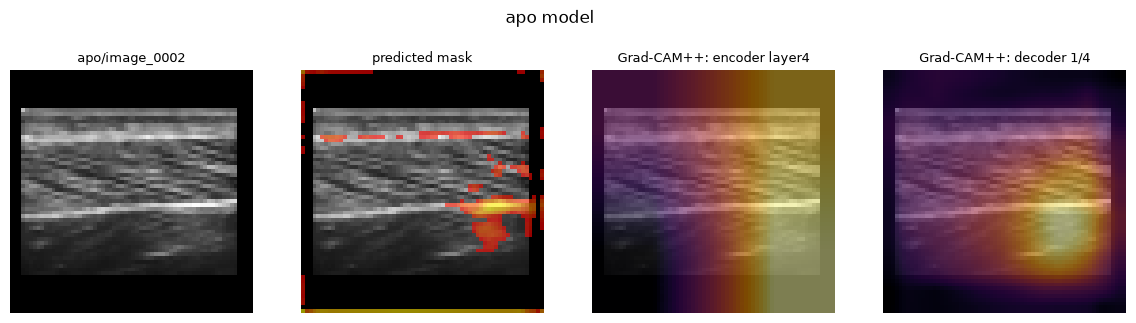

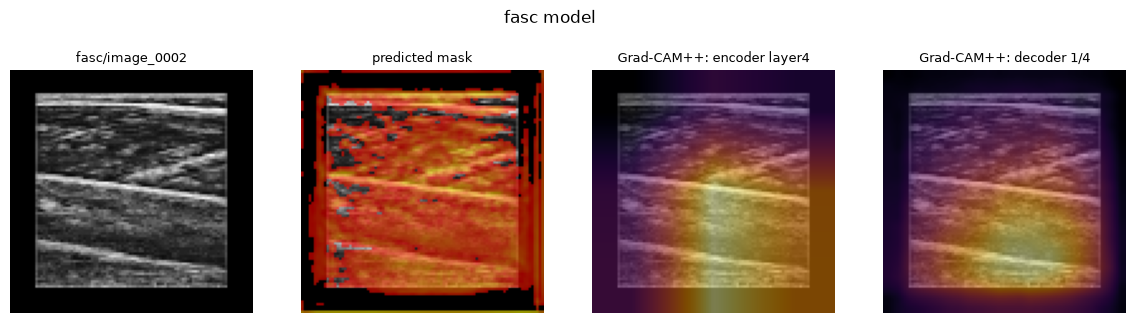

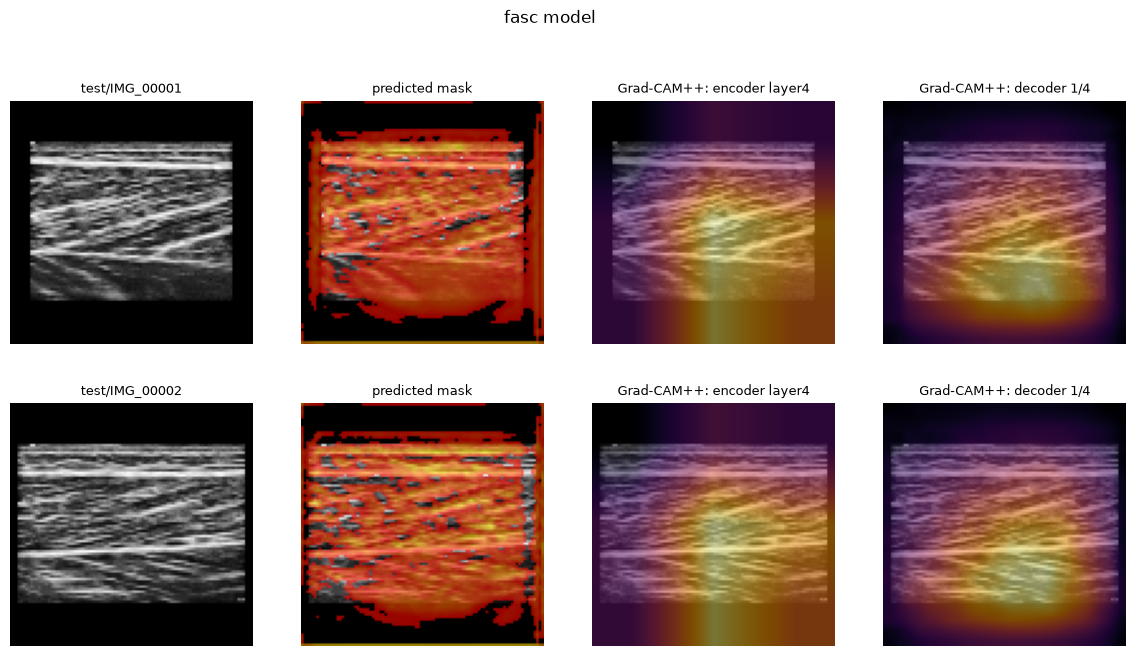

In [39]:
class CAM:
    """Grad-CAM / Grad-CAM++ on one layer."""
    def __init__(self, model, layer):
        self.model, self.act, self.grad = model, None, None
        self.h = layer.register_forward_hook(self._hook)
    def _hook(self, m, i, o):
        self.act = o
        o.register_hook(lambda g: setattr(self, 'grad', g))
    def remove(self):
        self.h.remove()
    def __call__(self, x, score_fn, plus=True):
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            out = self.model(x)
            score_fn(out).backward()
        A, G = self.act.detach()[0], self.grad.detach()[0]
        if plus:
            g2, g3 = G ** 2, G ** 3
            den = 2 * g2 + A.sum((1, 2), keepdim=True) * g3
            alpha = g2 / torch.where(den != 0, den, torch.ones_like(den))
            w = (alpha * F.relu(G)).sum((1, 2))
        else:
            w = G.mean((1, 2))
        cam = F.relu((w[:, None, None] * A).sum(0))
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), out.detach()

def seg_score(out):
    m = (torch.sigmoid(out) > 0.5).float()
    return (out * m).sum() / (m.sum() + 1) if m.sum() > 0 else out.mean()

def cam_panel(kind, keys, fname):
    model, c = MODELS[kind], BEST[kind]
    layers = [('encoder layer4', model.enc.layer4), ('decoder 1/4', model.dec[2])]
    sub = all_df.set_index('key').loc[keys].reset_index()
    X = build_arrays(sub, c['size'], c['clip'], with_mask=False)[0]
    fig, axes = plt.subplots(len(keys), 2 + len(layers), figsize=(3.6 * (2 + len(layers)), 3.6 * len(keys)), squeeze=False)
    for i, k in enumerate(keys):
        x = torch.from_numpy(X[i])[None, None].to(DEVICE).float() / 255
        with torch.no_grad():
            prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
        axes[i, 0].imshow(X[i], cmap='gray'); axes[i, 0].set_title(k, fontsize=9)
        axes[i, 1].imshow(X[i], cmap='gray'); axes[i, 1].imshow(np.ma.masked_where(prob < .5, prob), cmap='autumn', alpha=.6)
        axes[i, 1].set_title('predicted mask', fontsize=9)
        for j, (lname, layer) in enumerate(layers):
            cam = CAM(model, layer); hm, _ = cam(x, seg_score); cam.remove()
            axes[i, 2 + j].imshow(X[i], cmap='gray'); axes[i, 2 + j].imshow(hm, cmap='inferno', alpha=.5)
            axes[i, 2 + j].set_title(f'Grad-CAM++: {lname}', fontsize=9)
    for ax in axes.ravel():
        ax.axis('off')
    fig.suptitle(f'{kind} model', y=1.0)
    show(fig, fname)

for kind in ['apo', 'fasc']:
    ho = SETS[kind][SETS[kind].holdout]
    cam_panel(kind, list(ho.key.iloc[:3]), f'gradcam_{kind}')
cam_panel('fasc', list(test_df.key.iloc[:2]), 'gradcam_fasc_test')

## 11. Part B: direct regression CNN, step 2 (contrast/size x log-FL)
**Labels.** Each training image gets PA / FL / MT from Part A, using its *true* mask for what it was annotated for and
the other model's prediction for the rest (aponeurosis images: true aponeuroses + predicted fascicles;
fascicle images: true fascicles + predicted aponeuroses). Images without all three values are dropped.
These are computed labels, so Part B can only be as good as Part A's geometry.

**Grid.** The best `b_top_k_preproc` size/contrast combos from Part A step 2 x log-transformed FL or not.
Score = scale-free MAE (each parameter's MAE divided by its SD, averaged), so log and raw targets compare fairly.

In [40]:
if CFG['run_part_b']:
    lab_csv = OUT / 'partB_labels.csv'
    if lab_csv.exists() and CFG['reuse_saved']:
        LAB = pd.read_csv(lab_csv)
    else:
        LAB = pd.concat([SETS['apo'][['key', 'group', 'holdout']].merge(measure_set(SETS['apo'], 'gt', 'pred'), on='key'),
                         SETS['fasc'][['key', 'group', 'holdout']].merge(measure_set(SETS['fasc'], 'pred', 'gt'), on='key')])
        LAB.to_csv(lab_csv, index=False)
    ok = LAB[['pa_deg', 'fl_mm', 'mt_mm']].notna().all(1) & LAB.pa_deg.between(2, 60) & LAB.fl_mm.between(10, 300) \
         & LAB.mt_mm.between(3, 80)
    LAB = LAB[ok].reset_index(drop=True)
    print(f'Part B labels: {len(LAB)} images ({(~LAB.holdout).sum()} train, {LAB.holdout.sum()} hold-out)')
    print(LAB[['pa_deg', 'fl_mm', 'mt_mm']].describe().round(2))
    LAB_TR = LAB[~LAB.holdout]

    # rank Part A's size/contrast combos by their average rank across both models
    ranks = sum(step2[k][1].score_mean.rank(ascending=False) for k in ['apo', 'fasc']).sort_values()
    pre = step2['apo'][0].drop_duplicates('cfg').set_index('cfg').loc[ranks.index[:CFG['b_top_k_preproc']], ['size', 'clip']]
    configs = [dict(cfg=f'{cid}_log{int(lg)}', size=int(r['size']), clip=float(r['clip']), log_fl=lg, kind='reg')
               for cid, r in pre.iterrows() for lg in CFG['b_log_fl']]
    sub = subsample(LAB_TR, CFG['subsample_frac'], CFG['seed'])
    Y_of = lambda d: d[['pa_deg', 'fl_mm', 'mt_mm']].values.astype(np.float32)
    def reg_data(c, d=sub):
        return build_arrays(d, c['size'], c['clip'], with_mask=False)[0], Y_of(d), d.group.values
    b2 = run_cv('B-step2', configs, reg_data,
                lambda c: dict(epochs=CFG['step2_epochs'], patience=CFG['step2_patience'], batch=CFG['step2_batch'],
                               lr=CFG['step2_lr'], log_fl=c['log_fl']),
                OUT / 'stepB2.csv')
    print(b2[1].round(4))
    top = b2[0][b2[0].cfg == b2[1].index[0]].iloc[0]
    BEST['B'] = dict(size=int(top['size']), clip=float(top['clip']), log_fl=bool(top['log_fl']))
    print('Part B best preprocessing:', BEST['B'])

## 12. Part B, step 3: batch size x learning rate (5-fold CV, full set)

In [41]:
if CFG['run_part_b']:
    cB = BEST['B']
    XB, _, _ = build_arrays(LAB_TR, cB['size'], cB['clip'], with_mask=False)
    YB = Y_of(LAB_TR)
    configs = [dict(cfg=f'b{b}_lr{lr:g}', batch=b, lr=lr, kind='reg', **cB) for b in CFG['batch_sizes'] for lr in CFG['lrs']]
    b3 = run_cv('B-step3', configs, lambda c: (XB, YB, LAB_TR.group.values),
                lambda c: dict(epochs=CFG['step3_epochs'], patience=CFG['step3_patience'], batch=c['batch'], lr=c['lr'],
                               log_fl=c['log_fl']),
                OUT / 'stepB3.csv')
    top = b3[0][b3[0].cfg == b3[1].index[0]].iloc[0]
    BEST['B'].update(batch=int(top['batch']), lr=float(top['lr']))
    fig, ax = plt.subplots(figsize=(6, 3.8))
    pv = b3[0].groupby(['batch', 'lr']).best_score.mean().unstack()
    pv.index.name, pv.columns.name = 'batch size', 'learning rate'
    heat(ax, -pv, 'Part B: CV scale-free MAE (lower = better)')
    show(fig, 'stepB3_heatmap')
    print('Part B best:', BEST['B'])

## 13. Part B, step 4 & 5: final regressor, metrics, Grad-CAM++ per output

In [42]:
if CFG['run_part_b']:
    cB, path = BEST['B'], OUT / 'final_B.pt'
    if CFG['reuse_saved'] and path.exists() and torch.load(path, map_location='cpu', weights_only=False)['cfg'] == cB:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        MODEL_B = RegR34().to(DEVICE); MODEL_B.load_state_dict(ck['state']); MODEL_B.eval()
        TN_B = TargetNorm(YB, cB['log_fl']); TN_B.__dict__.update(ck['tn'])
        print('Part B: loaded', path)
    else:
        a, b = internal_split(LAB_TR, CFG['seed'])
        MODEL_B, TN_B, res, histB = fit('reg', XB[a], YB[a], XB[b], YB[b], epochs=CFG['final_epochs'],
                                        patience=CFG['final_patience'], batch=cB['batch'], lr=cB['lr'], log_fl=cB['log_fl'])
        MODEL_B.eval()
        torch.save(dict(state=MODEL_B.state_dict(), cfg=cB, tn=TN_B.__dict__), path)
        print(f'Part B: best epoch {res["best_epoch"]}, score {res["best_score"]:.4f}')
    del XB

    LAB_HO = LAB[LAB.holdout]
    XH = build_arrays(LAB_HO, cB['size'], cB['clip'], with_mask=False)[0]
    PH = TN_B.decode(predict(MODEL_B, XH))
    metrics_B = pd.DataFrame([reg_metrics(LAB_HO[c], PH[:, i], n) for i, (c, n) in
                              enumerate([('pa_deg', 'PA (deg)'), ('fl_mm', 'FL (mm)'), ('mt_mm', 'MT (mm)')])])
    metrics_B.to_csv(OUT / 'metrics_B_holdout.csv', index=False)
    print('\nPart B, hold-out images (reference = labels computed by Part A from true masks):')
    print(metrics_B.round(3).to_string(index=False))

    XT = build_arrays(test_df, cB['size'], cB['clip'], with_mask=False)[0]
    PT = TN_B.decode(predict(MODEL_B, XT))
    test_B = test_df[['key', 'name']].assign(pa_deg=PT[:, 0], fl_mm=PT[:, 1], mt_mm=PT[:, 2])
    sub_B = finalize(test_B, fallback); sub_B.to_csv(OUT / 'submission_B.csv', index=False)
    ens = test_A[['key', 'name']].copy()
    for c in ['pa_deg', 'fl_mm', 'mt_mm']:
        ens[c] = np.nanmean(np.c_[test_A[c].values, test_B[c].values], axis=1)
    sub_E = finalize(ens, fallback); sub_E.to_csv(OUT / 'submission_ensemble.csv', index=False)

    # Grad-CAM++ for each output of the regressor
    heads = [('PA', 0), ('FL', 1), ('MT', 2)]
    keys = list(test_df.key.iloc[:3])
    sub = test_df.set_index('key').loc[keys].reset_index()
    X = build_arrays(sub, cB['size'], cB['clip'], with_mask=False)[0]
    fig, axes = plt.subplots(len(keys), 1 + 2 * len(heads), figsize=(3.2 * (1 + 2 * len(heads)), 3.3 * len(keys)), squeeze=False)
    for i, k in enumerate(keys):
        x = torch.from_numpy(X[i])[None, None].to(DEVICE).float() / 255
        axes[i, 0].imshow(X[i], cmap='gray'); axes[i, 0].set_title(k, fontsize=9)
        for j, (hn, hi) in enumerate(heads):
            for jj, (lname, layer) in enumerate([('layer3', MODEL_B.enc.layer3), ('layer4', MODEL_B.enc.layer4)]):
                cam = CAM(MODEL_B, layer); hm, _ = cam(x, lambda o, hi=hi: o[0, hi]); cam.remove()
                ax = axes[i, 1 + 2 * j + jj]
                ax.imshow(X[i], cmap='gray'); ax.imshow(hm, cmap='inferno', alpha=.5)
                ax.set_title(f'{hn} | {lname}', fontsize=9)
    for ax in axes.ravel():
        ax.axis('off')
    fig.suptitle('Part B: Grad-CAM++ per output (layer3 = finer, layer4 = coarser)', y=1.0)
    show(fig, 'gradcam_B')

## 14. Summary and submission

In [43]:
choice = CFG['final_submission'] if CFG['run_part_b'] else 'A'
final = {'A': sub_A, 'B': globals().get('sub_B'), 'ensemble': globals().get('sub_E')}[choice]
sample = pd.read_csv(DATA / 'sample_submission.csv', sep=None, engine='python', encoding='utf-8-sig')
assert list(final.columns) == list(sample.columns), (final.columns, sample.columns)
final.to_csv(OUT / 'submission.csv', index=False)
pd.DataFrame(BEST).T.to_csv(OUT / 'best_configs.csv')
print('best configurations:'); print(pd.DataFrame(BEST).T)
print('\nsegmentation (hold-out):'); print(seg_table.round(4).to_string(index=False))
print('\nPart A PA/FL/MT (hold-out):'); print(metrics_A.round(3).to_string(index=False))
if CFG['run_part_b']:
    print('\nPart B PA/FL/MT (hold-out):'); print(metrics_B.round(3).to_string(index=False))
print(f'\nsubmission.csv = Part {choice}, {len(final)} rows -> {OUT / "submission.csv"}')
print(final.head())

best configurations:
      size  clip  batch     lr
apo   64.0   0.0    2.0  0.001
fasc  96.0   2.0    2.0  0.001

segmentation (hold-out):
model  n   Dice  Dice_sd    IoU
  apo  1 0.3292      NaN 0.1971
 fasc  1 0.0304      NaN 0.0154

Part A PA/FL/MT (hold-out):
parameter  n  failed   MSE  RMSE  MAE  MPE_pct  MAPE_pct  R2
 PA (deg)  0       1   NaN   NaN  NaN      NaN       NaN NaN
  FL (mm)  0       1   NaN   NaN  NaN      NaN       NaN NaN
  MT (mm)  1       0 0.533  0.73 0.73    3.995     3.995 NaN

submission.csv = Part A, 5 rows -> umud_outputs/submission.csv
        image_id  pa_deg   fl_mm   mt_mm
0  IMG_00001.tif   8.712  32.372  10.720
1  IMG_00002.tif   8.712  32.372  18.052
2  IMG_00003.tif  10.024  39.712  20.246
3  IMG_00004.tif   7.399  30.000  23.946
4  IMG_00005.tif   8.712  32.372  18.385
